# Lumped-element detectors

In lumped-element experiments, a static magnetic field lets axion dark matter drive oscillating flux through a pickup circuit. A tuned LC circuit reads the signal. In this walkthrough we describe detectors as design documents, solve toroidal, solenoidal and CORE geometries, compare them with long-detector formulas, and check convergence. The [reach and optimization notebook](reach_optimization.ipynb) turns the solved couplings into scan sensitivity.

## Coupling

In the magnetoquasistatic (MQS) limit, the detector is small compared with the electromagnetic wavelength. Pickup test current $I$ produces vector potential $\mathbf A_I$; its magnetic energy determines inductance $L_p$. The coupling to the static field $\mathbf B_{\rm lab}$ is

$$
\Psi = \frac{1}{I}\int \mathbf A_I\cdot\mathbf B_{\rm lab}\,d^3x,
\qquad \Phi_a = \kappa_a\Psi.
$$

Here $\Phi_a$ is axion flux amplitude and $\kappa_a$ is effective source amplitude. In SI, $\Psi$ is in $\mathrm{H\,T\,m^2}$, $L_p$ in H and $\kappa_a$ in $\mathrm{H^{-1}}$. The scan figure of merit must meet a requirement:

$$
\mathcal F = \frac{\Psi^4}{L_p^2} \geq \mathcal F_{\rm req}.
$$

$\mathcal F_{\rm req}$ depends on target coupling, frequency band, live time and readout noise.

In [1]:
import json, math, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from IPython.display import Image, display

import axionfem as af

print("axionFEM", af.__version__)
MU0 = 1.25663706212e-6                    # CODATA 2018 [H/m], as in the C++ core
RUNS = Path(tempfile.mkdtemp(prefix="axf_lumped_"))   # solver run directories
ROOT = Path.cwd().parent                  # repository root when run from examples/
plt.rcParams.update({"figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# fixed categorical order: one hue per topology
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"
COL = {"toroid": BLUE, "solenoid": ORANGE, "core": GREEN}


def solve(design, tag, **kw):
    """Solve in RUNS/tag and report the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    w = [x for x in (r.data.get("warnings") or []) if "background field is present" not in x]
    print(f"  {tag}: {r.data['mesh']['dofs']} DOFs" + (f", warnings: {w}" if w else ""))
    return r

axionFEM 0.1.0


## Design documents

An axisymmetric JSON design specifies the geometry, materials and currents. `af.templates()` lists the built-in designs with their parameters and units: the toroid has an azimuthal magnetic field, the solenoid an axial field, and CORE encloses a split solenoid in a superconducting cavity.

We list the templates and the parameters of the toroid.

In [2]:
for t in af.templates():
    print(f"{t['name']}: {t['description'][:110]}...")
print()
for k, p in af.templates()[0]["parameters"].items():
    print(f"    {k:8s} default {str(p['default']):12s} [{p['units'] or '-':2s}]  {p['meaning']}")

toroid: Toroidal magnet (ABRACADABRA / DMRadio-GUT topology). The static field B_phi fills the rectangular box y R < r...
solenoid: Solenoid magnet with an immersed shorted coaxial pickup (DMRadio-m^3 topology). The winding (inner radius R, t...
core: CORE topology (DMRadio-Core): a split solenoid of inner radius Rc, thickness tw and height H drives an axial f...

    H        default 2.0          [m ]  height of the field box
    NI       default 1000000.0    [A ]  total ampere-turns of the toroidal winding
    R        default 2.0          [m ]  outer radius of the field box
    f        default 0.02*R       [m ]  outer corner radius of the sheath
    g        default 0.005*R      [m ]  clearance between winding and sheath
    ts       default 0.005*R      [m ]  sheath wall thickness
    tw       default 0.01*R       [m ]  winding thickness
    y        default exp(-0.5)    [- ]  inner radius of the field box as a fraction of R


`af.template()` returns a `Design`. Numbers and expression strings are accepted: changing `R` also updates `tw` when it is defined as `"0.01*R"`. `with_params()` copies; `set()` edits in place.

In [3]:
tor = af.template("toroid", R=1.0, H=2.0)
print(tor)                                   # parameters as written
print(tor.resolved_params())                 # parameters as evaluated

tor2 = tor.with_params(R=1.5)                # a modified copy; tw = 0.01*R follows R
print(f"R = {tor2.resolved_params()['R']} m -> tw = {tor2.resolved_params()['tw']:.4f} m")

tor2.set(y=0.55, NI="2e6")                   # numbers or expressions
print(tor2)
try:
    tor2.set(Z=1.0)
except KeyError as e:
    print("KeyError:", e)

Design('toroid'; H=2.0, NI=1000000.0, R=1.0, f=0.02*R, g=0.005*R, ts=0.005*R, tw=0.01*R, y=exp(-0.5))
{'H': 2.0, 'NI': 1000000.0, 'R': 1.0, 'f': 0.02, 'g': 0.005, 'ts': 0.005, 'tw': 0.01, 'y': 0.6065306597126334}
R = 1.5 m -> tw = 0.0150 m
Design('toroid'; H=2.0, NI=2e6, R=1.5, f=0.02*R, g=0.005*R, ts=0.005*R, tw=0.01*R, y=0.55)
KeyError: "unknown parameter 'Z'; known parameters: H, NI, R, f, g, ts, tw, y"


`doc` is an editable dictionary. Regions define geometry and materials (later regions overwrite earlier ones where they overlap); windings define currents; `pickup` selects the readout conductor. The toroid's winding surrounds the field region, and a slit niobium sheath forms its pickup; the ideal Meissner model excludes magnetic field from superconducting material.

In [4]:
tor = af.template("toroid", R=1.0, H=2.0)
doc = tor.doc
print("top-level keys:", list(doc))
print("regions:", [(r["name"], r["material"]) for r in doc["regions"]])
print("windings:", doc["windings"])
print("pickup:", doc["pickup"], "| mesh:", doc["mesh"])

top-level keys: ['description', 'mesh', 'name', 'notes', 'parameters', 'pickup', 'regions', 'schema', 'superconductors', 'windings']
regions: [('winding', 'winding'), ('sheath', 'nb')]
windings: [{'ampere_turns': 'NI', 'name': 'toroid', 'region': 'winding', 'type': 'poloidal'}]
pickup: {'conductor': 'sheath', 'type': 'azimuthal'} | mesh: {'order': 2, 'size': 'max(R, H)/30', 'surface_size': 'min(ts, g, tw)'}


`validate()` checks the document and returns evaluated parameters. Errors identify the failing JSON path and, where available, suggest a correction. `save()` writes JSON and `af.load()` restores a `Design`.

In [5]:
print("valid:", tor.validate()["ok"])

mistakes = {
    "inner radius outside the outer one (y = 1.5)": lambda d: d.set(y=1.5),
    "expression with an unknown name":              lambda d: d.set(H="2*Q"),
    "unknown material":                              lambda d: d.doc["regions"][0].update(material="unobtainium"),
    "pickup on a body that does not exist":          lambda d: d.doc["pickup"].update(conductor="shield"),
}
for what, mistake in mistakes.items():
    d = tor.copy()
    mistake(d)
    try:
        d.validate()
        print(f"{what}: no error?")
    except af.AxionFEMError as e:
        print(f"{what}:\n    {e}")

path = tor.save(RUNS / "toroid_R1_H2.json")
back = af.load(path)
print(f"\n{path.name}: {path.stat().st_size} bytes;  round trip identical: {back.doc == tor.doc}")

valid: True
inner radius outside the outer one (y = 1.5):
    range must satisfy min < max (got 1.49, 1.01) [at /regions/0/shape/frame/r]
expression with an unknown name:
    parameter 'H' refers to unknown name 'Q' [at /parameters/H] Hint: Define it under "parameters" or use a number.
unknown material:
    unknown material 'unobtainium' [at /regions/0/material] Hint: Define it under "materials" or use one of: air, copper, copper_classical, iron, iron_knee, nb, superconductor, vacuum, winding.
pickup on a body that does not exist:
    pickup conductor 'shield' is not a region or curve [at /pickup/conductor]

toroid_R1_H2.json: 1884 bytes;  round trip identical: True


## Toroid model

`template` creates the design; `validate` checks it.

We build, validate and solve the toroid to obtain its coupling.

In [6]:
print(tor)
print("validate:", tor.validate()["ok"])
res_t = solve(tor, "toroid")
print(res_t.summary().split("\n  benchmark ")[0])  # the figures of merit (per-benchmark lines follow in the full summary)
print("results.json sections:", list(res_t.data))

Design('toroid'; H=2.0, NI=1000000.0, R=1.0, f=0.02*R, g=0.005*R, ts=0.005*R, tw=0.01*R, y=exp(-0.5))
validate: True
  toroid: 79774 DOFs
design 'toroid'
  Psi      = 9.847e-08 H T m^2  (0.07836 T m^3 natural)
  L_p      = 4.773e-07 H
  W_mag    = 1.021e+05 J
  F        = 4.128e-16 T^4 H^2 m^8
  g        = 0.1211
  |B|max   = 0.3297 T  at r = 0.607 m, z = -0.582 m (winding)
  SC surface peak [sheath] = 4.761e-18 T
results.json sections: ['benchmarks', 'checks', 'coupling', 'design', 'fields', 'forces', 'geometry', 'linear', 'mesh', 'pickup', 'static', 'timing', 'version', 'warnings', 'windings']


Read `warnings`, `checks` and `mesh` before interpreting the summary. Color shows the static field; pink lines show the pickup field.

We display a toroid cross-section to inspect the static and pickup fields.

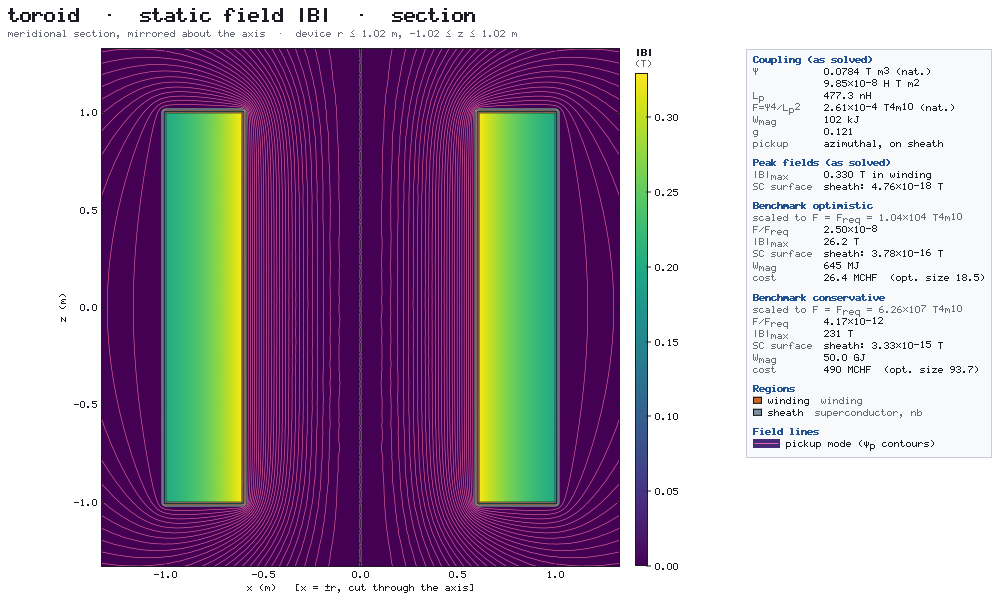

In [7]:
display(Image(filename=str(res_t.png(RUNS / "toroid_section.png", view="section", quantity="Bmag",
                                     width=1000, height=600)), width=700))

### Results

`coupling` also reports natural Heaviside–Lorentz values: $\Psi$ in $\mathrm{T\,m^3}$, $L_p$ in metres and $\mathcal F$ in $\mathrm{T^4\,m^{10}}$. The flux calculation uses natural $\kappa_a$ in $\mathrm{m^{-1}}$. Unit conventions must remain consistent. Geometric factor `g` uses the radius including walls; it differs from photon coupling. We report coupling and axion flux and compare element orders; the mesh should then be refined before design decisions.

In [8]:
c = res_t.coupling
Psi_n, L_n, W_J, R_dev = c["Psi_natural_T_m3"], c["L_p_natural_m"], c["W_mag_J"], c["device_radius_m"]
print(f"Psi = {c['Psi_SI_H_T_m2']:.4e} H T m^2 = {Psi_n:.4f} T m^3;  L_p = {c['L_p_H']*1e9:.1f} nH = {L_n:.4f} m;  "
      f"F = {c['F_natural_T4_m10']:.4e} T^4 m^10")
print(f"W_mag = {W_J/1e3:.1f} kJ at NI = {tor.resolved_params()['NI']:.0e} A-turns, B_max = {res_t.B_max:.3f} T")
print(f"g = {c['g_factor']:.5f}  (by hand: Psi^2/(L_p W R^2) = {Psi_n**2 / (L_n * MU0 * W_J * R_dev**2):.5f}, R = {R_dev:.4f} m)")

# kappa_a for g = 1e-19 GeV^-1, rho = 0.3 GeV/cm^3 (natural units -> m^-1), and the flux it drives
GEV_J, HBARC = 1.602176634e-10, 1.973269804e-7 * 1.602176634e-19        # J/GeV, hbar*c [J m]
kappa_m = 1e-19 / GEV_J * math.sqrt(2 * 0.3 * GEV_J * 1e6 * HBARC)
PHI0 = 2.067833848e-15
print(f"kappa_a(1e-19 GeV^-1) = {kappa_m:.6e} m^-1")
print(f"Phi_a = kappa_a Psi = {kappa_m * Psi_n:.3e} Wb = {kappa_m * Psi_n / PHI0:.2e} Phi_0 at B_max = {res_t.B_max:.2f} T")

print("\norder-3 check (same mesh):")
res_t3 = solve(tor, "toroid_p3", order=3)
for k in ("Psi_SI_H_T_m2", "L_p_H", "F_SI_T4_H2_m8", "W_mag_J", "g_factor"):
    print(f"  {k:15s} p2 {c[k]:.6e}   p3 {res_t3.coupling[k]:.6e}   rel. change {res_t3.coupling[k] / c[k] - 1:+.1e}")

Psi = 9.8475e-08 H T m^2 = 0.0784 T m^3;  L_p = 477.3 nH = 0.3798 m;  F = 2.6140e-04 T^4 m^10
W_mag = 102.1 kJ at NI = 1e+06 A-turns, B_max = 0.330 T
g = 0.12112  (by hand: Psi^2/(L_p W R^2) = 0.12112, R = 1.0200 m)
kappa_a(1e-19 GeV^-1) = 1.088100e-24 m^-1
Phi_a = kappa_a Psi = 8.527e-26 Wb = 4.12e-11 Phi_0 at B_max = 0.33 T

order-3 check (same mesh):
  toroid_p3: 179281 DOFs
  Psi_SI_H_T_m2   p2 9.847478e-08   p3 9.847463e-08   rel. change -1.5e-06
  L_p_H           p2 4.772929e-07   p3 4.772934e-07   rel. change +1.1e-06
  F_SI_T4_H2_m8   p2 4.127910e-16   p3 4.127876e-16   rel. change -8.2e-06
  W_mag_J         p2 1.021005e+05   p3 1.021002e+05   rel. change -3.2e-06
  g_factor        p2 1.211204e-01   p3 1.211202e-01   rel. change -8.8e-07


### Length sweep

The sweep compares finite toroids with their long limit; finite walls change that limit.

We vary the toroid length and extrapolate its geometric factor to check the long limit.

In [9]:
def g_long_toroid(p, R_dev):
    """Long-limit g of the toroid template's cross-section (walls of finite thickness, uniform J in the legs)."""
    y, R, tw = p["y"], p["R"], p["tw"]
    r1, r2 = y * R - tw, y * R
    def B(r):                                  # B_phi(r) up to a constant
        if r1 <= r < r2: return (r * r - r1 * r1) / (r2 * r2 - r1 * r1) / r
        if r2 <= r < R: return 1.0 / r
        if R <= r < R + tw: return (1.0 - (r * r - R * R) / ((R + tw) ** 2 - R * R)) / r
        return 0.0
    edges = [r1, r2, R, R + tw]
    I1 = sum(quad(B, a, b)[0] for a, b in zip(edges[:-1], edges[1:]))
    I2 = sum(quad(lambda r: B(r) ** 2 * r, a, b)[0] for a, b in zip(edges[:-1], edges[1:]))
    r_i = y * R - tw - p["g"] - p["ts"]
    return r_i ** 2 * I1 ** 2 / (I2 * R_dev ** 2), dict(I1=I1, I2=I2, r_i=r_i)

HR = np.array([1, 2, 4, 8, 16])
long_t = []
for h in HR:
    d = af.template("toroid", R=1.0, H=float(h))
    d.doc["mesh"]["size"] = "R/12"
    long_t.append(solve(d, f"toroid_H{h}"))
g_t = np.array([r.g for r in long_t])
p_t = af.template("toroid", R=1.0).resolved_params()
g_inf_t, parts_t = g_long_toroid(p_t, long_t[0].coupling["device_radius_m"])
fit_t = np.polyfit(1 / HR[-3:], g_t[-3:], 2)
print(f"\nideal long limit 1/(2e)          = {1 / (2 * math.e):.5f}")
print(f"long limit of this cross-section = {g_inf_t:.5f}  (walls: r_i = {parts_t['r_i']:.4f} m, R_dev = {long_t[0].coupling['device_radius_m']:.4f} m)")
print(f"FEM, extrapolated to H -> inf    = {fit_t[-1]:.5f}  ({fit_t[-1] / g_inf_t - 1:+.1%})")
for h, r in zip(HR, long_t):
    print(f"  H/R = {h:2d}: g = {r.g:.5f} = {r.g / g_inf_t:.3f} g_inf")

  toroid_H1: 43016 DOFs
  toroid_H2: 72406 DOFs
  toroid_H4: 134583 DOFs
  toroid_H8: 278844 DOFs
  toroid_H16: 685257 DOFs

ideal long limit 1/(2e)          = 0.18394
long limit of this cross-section = 0.17119  (walls: r_i = 0.5865 m, R_dev = 1.0200 m)
FEM, extrapolated to H -> inf    = 0.17095  (-0.1%)
  H/R =  1: g = 0.09489 = 0.554 g_inf
  H/R =  2: g = 0.12112 = 0.708 g_inf
  H/R =  4: g = 0.14133 = 0.826 g_inf
  H/R =  8: g = 0.15460 = 0.903 g_inf
  H/R = 16: g = 0.16239 = 0.949 g_inf


We plot the geometric factor and normalized coupling, inductance and energy to identify end effects.

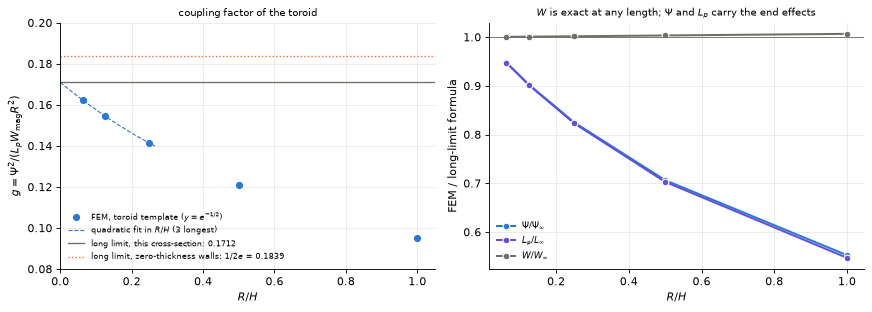

In [10]:
# The long-limit Psi, L and W of the same cross-section (per ampere-turn, SI), to see which quantity carries the end effects
NI = p_t["NI"]
B0 = MU0 * NI / (2 * math.pi)                       # B_phi = B0 * B(r) of g_long_toroid
ratios = {"$\\Psi/\\Psi_\\infty$": [], "$L_p/L_\\infty$": [], "$W/W_\\infty$": []}
for h, r in zip(HR, long_t):
    cc = r.coupling
    ratios["$\\Psi/\\Psi_\\infty$"].append(cc["Psi_natural_T_m3"] / (math.pi * parts_t["r_i"] ** 2 * B0 * parts_t["I1"]))
    ratios["$L_p/L_\\infty$"].append(cc["L_p_H"] / (MU0 * math.pi * parts_t["r_i"] ** 2 / h))
    ratios["$W/W_\\infty$"].append(cc["W_mag_J"] / (math.pi * h * B0 ** 2 * parts_t["I2"] / MU0))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
x = np.linspace(0, 1.05, 100)
ax0.plot(1 / HR, g_t, "o", ms=8, color=BLUE, mec="white", mew=1.5, label="FEM, toroid template ($y=e^{-1/2}$)")
ax0.plot(x[x <= 0.27], np.polyval(fit_t, x[x <= 0.27]), color=BLUE, lw=1, ls="--", label="quadratic fit in $R/H$ (3 longest)")
ax0.axhline(g_inf_t, color=GREY, lw=1.2, label=f"long limit, this cross-section: {g_inf_t:.4f}")
ax0.axhline(1 / (2 * math.e), color=ORANGE, lw=1.2, ls=":", label=f"long limit, zero-thickness walls: $1/2e$ = {1/(2*math.e):.4f}")
ax0.set_xlabel("$R/H$"); ax0.set_ylabel(r"$g=\Psi^2/(L_pW_{\rm mag}R^2)$"); ax0.set_xlim(0, 1.05); ax0.set_ylim(0.08, 0.2)
ax0.legend(fontsize=7.5, loc="lower left"); ax0.set_title("coupling factor of the toroid", fontsize=9)
for (lab, v), col in zip(ratios.items(), (BLUE, VIOLET, GREY)):
    ax1.plot(1 / HR, v, "o-", ms=6, color=col, mec="white", label=lab)
ax1.axhline(1, color=GREY, lw=0.8)
ax1.set_xlabel("$R/H$"); ax1.set_ylabel("FEM / long-limit formula"); ax1.legend(fontsize=8)
ax1.set_title(r"$W$ is exact at any length; $\Psi$ and $L_p$ carry the end effects", fontsize=9)
fig.tight_layout(); plt.show()

## Compare three pickup geometries

- A **toroid** confines an azimuthal field inside a superconducting pickup sheath.
- A **solenoid** supplies an axial field to a coaxial pickup.
- **CORE** places a split solenoid inside a superconducting toroidal cavity.

The dimensionless geometric factor compares signal coupling at fixed stored energy and device radius:

$$
g=\frac{\Psi^2}{L_p W_{\rm mag}R_{\rm dev}^2}.
$$

Here $\Psi$ is signal coupling, $L_p$ pickup inductance, $W_{\rm mag}$ stored energy and $R_{\rm dev}$ the outer radius of all regions. This equation uses natural Heaviside–Lorentz units; `res.g` returns the dimensionless result.

The templates below have approximately one-metre outer radii and two-metre heights.

We build and solve solenoid and CORE models for comparison with the toroid.

In [11]:
sol = af.template("solenoid", R=1.0, H=2.0)
core = af.template("core", Rc=0.4, H=2.0)
res_s = solve(sol, "solenoid")
res_c = solve(core, "core")
print(sol.resolved_params())
print({k: round(v, 4) for k, v in core.resolved_params().items()})
designs = {"toroid": (tor, res_t), "solenoid": (sol, res_s), "core": (core, res_c)}

  solenoid: 73566 DOFs
  core: 191118 DOFs
{'H': 2.0, 'NI': 1000000.0, 'R': 1.0, 'g': 0.005, 'tc': 0.005, 'tp': 0.01, 'tw': 0.01, 'x': 0.534}
{'H': 2.0, 'NI': 1000000.0, 'Rc': 0.4, 'a': 0.432, 'b': 1.0, 'cl': 0.02, 'f': 0.02, 'fl': 0.0012, 'gc': 0.008, 'gn': 0.004, 'h': 2.0, 'iron_dz': 0.008, 'iron_r0': 0.0, 'iron_r1': 1.004, 'iron_t': 0.0, 'tw': 0.008, 'w': 0.004}


We plot the solenoid and CORE cross-sections. Static fields are on the left, pickup fields on the right.

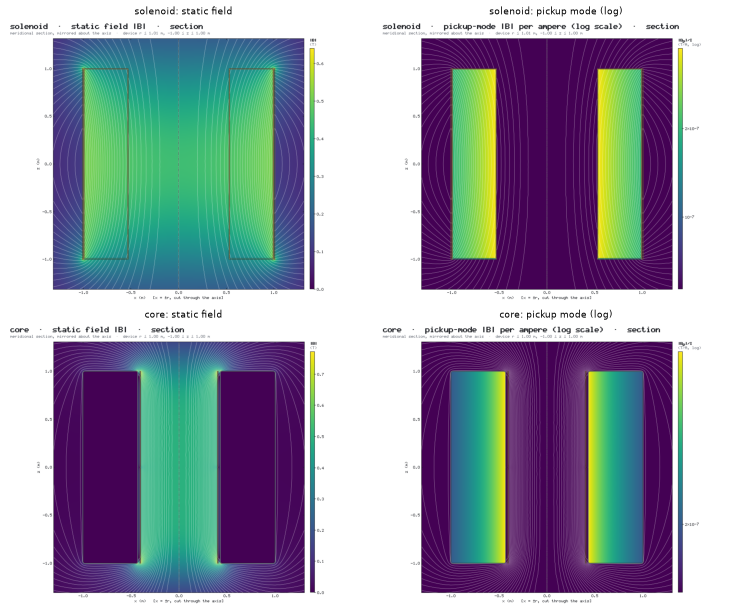

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(10.5, 8.6), dpi=72)
for row, name in zip(axs, ("solenoid", "core")):
    r = designs[name][1]
    for ax, (q, log, lab) in zip(row, (("Bmag", False, "static field"), ("pickup_Bmag", True, "pickup mode (log)"))):
        p = r.png(RUNS / f"{name}_{q}.png", view="section", quantity=q, log_scale=log, width=900, height=720, annotate=False)
        ax.imshow(plt.imread(p)); ax.axis("off"); ax.set_title(f"{name}: {lab}", fontsize=9)
fig.tight_layout(); plt.show()

### Comparison results

The table reports coupling, inductance, stored energy and the amplitude needed to meet the scan requirement (see the reach and optimization notebook). Regular surface peaks exclude sharp-corner neighborhoods.

We tabulate coupling and field requirements to compare the three geometries.

In [13]:
def g_long(name, p):
    if name == "solenoid":
        x = p["x"]; return (1 - x * x) ** 2 / (4 * math.log(1 / x))
    y = p["y"] if name == "toroid" else p["a"] / p["b"]
    return y * y * math.log(1 / y)

rows = []
print(f"{'':9s}{'Psi [T m^3]':>12s}{'L_p [nH]':>10s}{'F [T^4m^10]':>13s}{'W [kJ]':>9s}{'g':>8s}{'g_long':>8s}{'R_dev':>7s}")
for name, (d, r) in designs.items():
    cc = r.coupling
    print(f"{name:9s}{cc['Psi_natural_T_m3']:12.4f}{cc['L_p_H']*1e9:10.1f}{cc['F_natural_T4_m10']:13.4e}{cc['W_mag_J']/1e3:9.1f}"
          f"{r.g:8.4f}{g_long(name, d.resolved_params()):8.4f}{cc['device_radius_m']:7.3f}")
print()
print(f"{'':9s}{'benchmark':>22s}{'F/F_req':>11s}{'ampl. x':>9s}{'B_max@req':>11s}{'SC surface@req':>16s}")
for name, (d, r) in designs.items():
    for b in r.data["benchmarks"]:
        sc = b["superconductor_surface_regular_at_req_T"]
        print(f"{name:9s}{b['name']:>22s}{b['F_over_F_req']:11.3e}{b['amplitude_scale']:9.1f}{b['B_max_at_req_T']:9.1f} T"
              f"{(f'{max(sc.values()):12.3g} T') if sc else '        (none)':>16s}")
fc = res_c.data["fields"]
print(f"\nCORE as solved: peak |B| on the cavity {fc['superconductor_surface_T']['cavity']:.3f} T at "
      f"{ {k: round(v, 3) for k, v in fc['superconductor_surface_location']['cavity'].items()} } "
      f"(cavity inner radius a = {core.resolved_params()['a']} m, ends at z = +-{core.resolved_params()['h'] / 2} m); "
      f"sharp corners: {fc['superconductor_sharp_corners'] or 'none'}")

          Psi [T m^3]  L_p [nH]  F [T^4m^10]   W [kJ]       g  g_long  R_dev
toroid         0.0784     477.3   2.6140e-04    102.1  0.1211  0.1839  1.020
solenoid       0.1430     245.5   1.0961e-02    681.9  0.1198  0.2036  1.010
core           0.0652     335.7   2.5365e-04    124.4  0.1011  0.1566  1.004

                      benchmark    F/F_req  ampl. x  B_max@req  SC surface@req
toroid               optimistic  2.504e-08     79.5     26.2 T      3.78e-16 T
toroid             conservative  4.174e-12    699.6    230.7 T      3.33e-15 T
solenoid             optimistic  1.050e-06     31.2     20.4 T          (none)
solenoid  conservative_solenoid  1.750e-11    488.9    319.7 T          (none)
core                 optimistic  2.430e-08     80.1     61.9 T          61.9 T
core               conservative  4.050e-12    704.9    544.5 T           545 T

CORE as solved: peak |B| on the cavity 0.772 T at {'r_m': 0.437, 'z_m': -1.001} (cavity inner radius a = 0.43200000000000005 m, ends at z

CORE's ideal Meissner model needs an explicit material field cap when scaling. The surface fields and caps are examined below.

## Vary the radius ratio

For long detectors with zero-thickness walls,

$$
g_{\rm tor}=y^2\ln(1/y),\qquad
g_{\rm sol}=\frac{(1-x^2)^2}{4\ln(1/x)}.
$$

Here $y$ is the toroid's inner-to-outer field-region radius ratio, and $x$ is the coaxial pickup's inner-to-outer radius ratio. `with_params` creates each variant. The sweep uses a coarser mesh and compares it with the default mesh at the template parameters. The cross-section limit `g_xsec` includes each template's wall thicknesses.

In [14]:
def integ(f, r0, r1, n=20001):
    """Trapezoid rule on a fine grid (the integrands are smooth on each piece)."""
    r = np.linspace(r0, r1, n); v = f(r)
    return float(np.sum((v[1:] + v[:-1]) * np.diff(r)) / 2)


def g_xsec(name, p):
    """Long limit of a template's own cross-section (finite walls, uniform current in the winding, normalized by R_dev)."""
    if name == "toroid":                                   # B_phi in the winding legs and the field box
        y, R, tw = p["y"], p["R"], p["tw"]; r1, r2 = y * R - tw, y * R
        pieces = [(lambda r: (r * r - r1 * r1) / (r2 * r2 - r1 * r1) / r, r1, r2), (lambda r: 1 / r, r2, R),
                  (lambda r: (1 - (r * r - R * R) / ((R + tw) ** 2 - R * R)) / r, R, R + tw)]
        I1 = sum(integ(f, a, b) for f, a, b in pieces); I2 = sum(integ(lambda r, f=f: f(r) ** 2 * r, a, b) for f, a, b in pieces)
        r_i, R_dev = y * R - tw - p["g"] - p["ts"], R + tw + p["g"] + p["ts"]
        return r_i ** 2 * I1 ** 2 / (I2 * R_dev ** 2)
    R, tw = p["R"], p["tw"]                                 # solenoid: coax gap x R < r < R - g - tc in a uniform B_z
    ri, ro, R_dev = p["x"] * R, R - p["g"] - p["tc"], R + tw
    I2 = R * R / 2 + integ(lambda r: ((R + tw - r) / tw) ** 2 * r, R, R + tw)
    return (ro * ro - ri * ri) ** 2 / (8 * math.log(ro / ri) * I2 * R_dev ** 2)


def sweep(base, pname, values, tag):
    out = []
    for v in values:
        d = base.with_params(**{pname: float(v)})
        d.doc["mesh"]["size"] = "R/12"
        out.append(d.solve(RUNS / f"{tag}_{v:.3f}", verbose=0).g)
    return np.array(out)


ys = np.array([0.4, 0.5, 0.55, math.exp(-0.5), 0.65, 0.7, 0.8])
xs = np.array([0.35, 0.45, 0.5, 0.534, 0.6, 0.7])
g_y = sweep(tor, "y", ys, "tor_y")
g_x = sweep(sol, "x", xs, "sol_x")
print(f"{len(ys) + len(xs)} solves; coarse vs default mesh at the template point: toroid "
      f"{g_y[3]:.5f} vs {res_t.g:.5f} (y = e^-1/2); solenoid {g_x[3]:.5f} vs {res_s.g:.5f}")
for lab, xv, gv in (("toroid  y", ys, g_y), ("solenoid x", xs, g_x)):
    i = int(np.argmax(gv))
    print(f"{lab}: " + "  ".join(f"{a:.3f}:{b:.4f}" for a, b in zip(xv, gv)) + f"   -> best on the grid {xv[i]:.3f}")

13 solves; coarse vs default mesh at the template point: toroid 0.12112 vs 0.12112 (y = e^-1/2); solenoid 0.11977 vs 0.11977
toroid  y: 0.400:0.1012  0.500:0.1168  0.550:0.1205  0.607:0.1211  0.650:0.1189  0.700:0.1134  0.800:0.0925   -> best on the grid 0.607
solenoid x: 0.350:0.1065  0.450:0.1164  0.500:0.1190  0.534:0.1198  0.600:0.1185  0.700:0.1084   -> best on the grid 0.534


cross-section long limits peak at y = 0.623 and x = 0.527 (grid step 0.003)


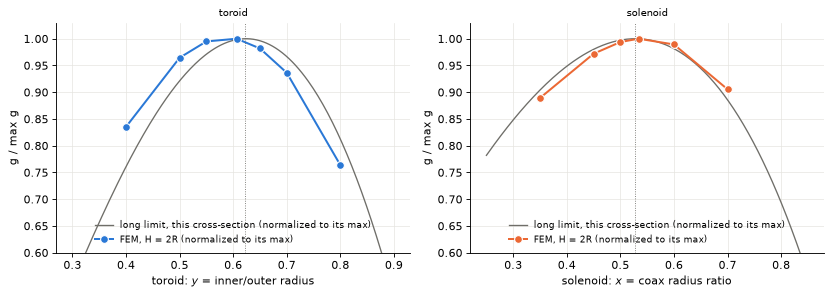

In [15]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10.5, 3.8))
yy, xx = np.linspace(0.3, 0.9, 200), np.linspace(0.25, 0.85, 200)
pt, ps = tor.resolved_params(), sol.resolved_params()
gl_t = np.array([g_xsec("toroid", dict(pt, y=v)) for v in yy])     # walls fixed at the template's values
gl_s = np.array([g_xsec("solenoid", dict(ps, x=v)) for v in xx])
print(f"cross-section long limits peak at y = {yy[np.argmax(gl_t)]:.3f} and x = {xx[np.argmax(gl_s)]:.3f} (grid step 0.003)")
for ax, grid, gl, xv, gv, col, lab in ((ax0, yy, gl_t, ys, g_y, BLUE, "toroid: $y$ = inner/outer radius"),
                                       (ax1, xx, gl_s, xs, g_x, ORANGE, "solenoid: $x$ = coax radius ratio")):
    ax.plot(grid, gl / gl.max(), color=GREY, lw=1.2, label="long limit, this cross-section (normalized to its max)")
    ax.plot(xv, gv / gv.max(), "o-", color=col, ms=7, mec="white", label="FEM, H = 2R (normalized to its max)")
    ax.axvline(grid[np.argmax(gl)], color=GREY, lw=0.8, ls=":")
    ax.set_xlabel(lab); ax.set_ylabel("g / max g"); ax.set_ylim(0.6, 1.03); ax.legend(fontsize=8, loc="lower center")
ax0.set_title("toroid", fontsize=9); ax1.set_title("solenoid", fontsize=9)
fig.tight_layout(); plt.show()

Each curve is normalized to its own maximum, so the plot compares preferred proportions rather than absolute coupling. The largest sampled value locates the optimum only to the grid spacing. Refine both mesh and parameter spacing, then compare designs at the same sensitivity target.

### Long-limit comparison

Toroid and CORE exchange static and pickup fields. Length and wall-thickness sweeps separate end and wall effects.

We vary the CORE length and extrapolate its geometric factor to check its long limit.

In [16]:
def g_long_core(p, R_dev):
    """Long-limit g of the CORE template's cross-section (coil of thickness tw with uniform J, cavity a < r < b)."""
    Rc, tw, a, b = p["Rc"], p["tw"], p["a"], p["b"]
    Bz = lambda r: 1.0 if r < Rc else (Rc + tw - r) / tw          # bore, then the winding
    I1 = quad(lambda r: Bz(r) * r, 0, Rc)[0] + quad(lambda r: Bz(r) * r, Rc, Rc + tw)[0]
    I2 = quad(lambda r: Bz(r) ** 2 * r, 0, Rc)[0] + quad(lambda r: Bz(r) ** 2 * r, Rc, Rc + tw)[0]
    return 2 * math.log(b / a) * I1 ** 2 / (I2 * R_dev ** 2)

E12 = math.exp(0.5)
long_c = []
for h in HR:
    d = af.template("core", Rc=1.0, H=float(h))
    d.set(b=f"a*{E12!r}")                                  # y = a/b = e^-1/2, as for the toroid
    d.doc["mesh"]["size"] = "Rc/6"
    long_c.append((d, solve(d, f"core_H{h}")))
p_c = long_c[0][0].resolved_params()
g_c = np.array([r.g for _, r in long_c])
g_inf_c = g_long_core(p_c, long_c[0][1].coupling["device_radius_m"])
fit_c = np.polyfit(1 / HR[-3:], g_c[-3:], 2)
print(f"\nCORE: y = a/b = {p_c['a'] / p_c['b']:.4f};  long limit of this cross-section {g_inf_c:.5f};  "
      f"FEM extrapolated {fit_c[-1]:.5f} ({fit_c[-1] / g_inf_c - 1:+.1%})")
for h, (_, r) in zip(HR, long_c):
    print(f"  H/R_c = {h:2d}: g = {r.g:.5f} = {r.g / g_inf_c:.3f} g_inf")

  core_H1: 52327 DOFs
  core_H2: 82053 DOFs
  core_H4: 141852 DOFs
  core_H8: 256313 DOFs
  core_H16: 474214 DOFs

CORE: y = a/b = 0.6065;  long limit of this cross-section 0.16014;  FEM extrapolated 0.15917 (-0.6%)
  H/R_c =  1: g = 0.05830 = 0.364 g_inf
  H/R_c =  2: g = 0.08670 = 0.541 g_inf
  H/R_c =  4: g = 0.11272 = 0.704 g_inf
  H/R_c =  8: g = 0.13222 = 0.826 g_inf
  H/R_c = 16: g = 0.14477 = 0.904 g_inf


We vary wall thickness and plot both geometries' coupling factors to separate end and wall effects.

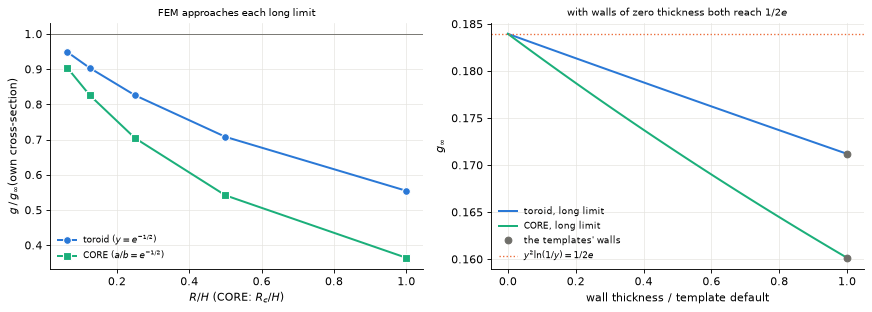

zero walls: toroid 0.183940, CORE 0.183940, 1/(2e) = 0.183940


In [17]:
# shrink every wall of both analytic cross-sections by a factor s -> 0
s_grid = np.linspace(0, 1, 41)
g_ts, g_cs = [], []
for s in s_grid:
    pt = dict(p_t, tw=s * p_t["tw"], g=s * p_t["g"], ts=s * p_t["ts"])
    g_ts.append(g_long_toroid(pt, p_t["R"] + s * (p_t["tw"] + p_t["g"] + p_t["ts"]))[0])
    tw, cl, w = s * p_c["tw"], s * p_c["cl"], s * p_c["w"]
    a = p_c["Rc"] + tw + cl + w
    g_cs.append(g_long_core(dict(p_c, tw=tw, a=a, b=a * E12), a * E12 + w))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
ax0.plot(1 / HR, g_t / g_inf_t, "o-", ms=7, color=BLUE, mec="white", label="toroid ($y=e^{-1/2}$)")
ax0.plot(1 / HR, g_c / g_inf_c, "s-", ms=7, color=GREEN, mec="white", label="CORE ($a/b=e^{-1/2}$)")
ax0.axhline(1, color=GREY, lw=0.8)
ax0.set_xlabel("$R/H$ (CORE: $R_c/H$)"); ax0.set_ylabel(r"$g\,/\,g_\infty$(own cross-section)")
ax0.set_title("FEM approaches each long limit", fontsize=9); ax0.legend(fontsize=8)
ax1.plot(s_grid, g_ts, color=BLUE, label="toroid, long limit")
ax1.plot(s_grid, g_cs, color=GREEN, label="CORE, long limit")
ax1.plot([1, 1], [g_inf_t, g_inf_c], "o", color=GREY, ms=6, label="the templates' walls")
ax1.axhline(1 / (2 * math.e), color=ORANGE, ls=":", lw=1.2, label="$y^2\\ln(1/y)=1/2e$")
ax1.set_xlabel("wall thickness / template default"); ax1.set_ylabel(r"$g_\infty$")
ax1.set_title("with walls of zero thickness both reach $1/2e$", fontsize=9); ax1.legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"zero walls: toroid {g_ts[0]:.6f}, CORE {g_cs[0]:.6f}, 1/(2e) = {1 / (2 * math.e):.6f}")

## Surface fields and convergence

`fields` reports winding and superconducting surface peaks at the solved currents. An ideal sharp corner has a singular field: use the corner flags and the peak away from corners when interpreting refinement. CORE's superconducting cavity diverts the coil's return flux around its walls.

We print the field summaries of the toroid and of CORE.

In [18]:
pc = core.resolved_params()
print(f"cavity: a = {pc['a']:.3f} m, b = {pc['b']:.3f} m, h = {pc['h']:.3f} m, wall w = {pc['w']*1e3:.0f} mm; "
      f"outer corners rounded with f = {pc['f']*1e3:.0f} mm, neck lips with fl = {pc['fl']*1e3:.1f} mm\n")

def show_fields(name, r):
    f = r.data["fields"]
    loc = {k: round(v, 4) if isinstance(v, float) else v for k, v in f["B_max_location"].items()}
    print(f"{name}: |B|max = {f['B_max_T']:.4f} T at {loc}")
    print("   per region [T]:", {k: round(v, 4) for k, v in f["by_region_T"].items()})
    for body, B in f["superconductor_surface_T"].items():
        where = {k: round(v, 4) for k, v in f["superconductor_surface_location"][body].items()}
        print(f"   superconductor '{body}': surface peak {B:.4g} T at {where}, "
              f"away from sharp corners {f['superconductor_surface_regular_T'][body]:.4g} T")
    print("   sharp corners:", f["superconductor_sharp_corners"] or "none")

show_fields("toroid", res_t)
show_fields("core", res_c)

cavity: a = 0.432 m, b = 1.000 m, h = 2.000 m, wall w = 4 mm; outer corners rounded with f = 20 mm, neck lips with fl = 1.2 mm

toroid: |B|max = 0.3297 T at {'r_m': 0.6065, 'region': 'winding', 'z_m': -0.5821}
   per region [T]: {'air': 0.3297, 'winding': 0.3297}
   superconductor 'sheath': surface peak 4.761e-18 T at {'r_m': 0.5915, 'z_m': 0.5028}, away from sharp corners 4.761e-18 T
   sharp corners: none
core: |B|max = 0.7725 T at {'r_m': 0.4369, 'region': 'air', 'z_m': -1.0006}
   per region [T]: {'air': 0.7725, 'coil_lower': 0.7573, 'coil_upper': 0.7574, 'neck': 0.0362}
   superconductor 'cavity': surface peak 0.7725 T at {'r_m': 0.4369, 'z_m': -1.0006}, away from sharp corners 0.7725 T
   sharp corners: none


The ideal Meissner model assumes the cavity remains superconducting. The next cell tests the surface-field cap after scaling to each scan requirement; `ok = False` means the rescaled fields exceed a configured cap, and the result does not establish a feasible detector.

In [19]:
for b in res_c.data["benchmarks"]:
    cap = b["caps_at_req"]
    print(f"{b['name']:13s}: amplitude x{b['amplitude_scale']:.1f} -> cavity surface {cap['sc_wall_T']:.1f} T "
          f"vs cap {cap['sc_wall_cap_T']} T: ok = {cap['ok']}")

optimistic   : amplitude x80.1 -> cavity surface 61.9 T vs cap 0.086 T: ok = False
conservative : amplitude x704.9 -> cavity surface 544.5 T vs cap 0.086 T: ok = False


Compare order 3 with order 2, then refine the mesh. Integrated quantities and local surface peaks can converge at different rates. The relative changes estimate sensitivity to these refinements; they do not provide a rigorous error bound.

In [20]:
res_c3 = solve(core, "core_p3", order=3)
fine = core.copy()
fine.doc["mesh"]["size"] = "max(b, H)/60"
fine.doc["mesh"]["surface_size"] = "min(w, gn)/4"
res_cf = solve(fine, "core_fine")

rows = {"Psi [H T m^2]": lambda r: r.Psi, "L_p [H]": lambda r: r.L_p, "W_mag [J]": lambda r: r.W, "g": lambda r: r.g,
        "cavity surface peak [T]": lambda r: r.data["fields"]["superconductor_surface_T"]["cavity"],
        "coil peak [T]": lambda r: r.data["fields"]["by_region_T"]["coil_lower"]}
print(f"{'':26s}{'order 2':>13s}{'order 3':>13s}{'rel.':>10s}{'fine mesh':>13s}{'rel.':>10s}")
for k, fn in rows.items():
    v2, v3, vf = fn(res_c), fn(res_c3), fn(res_cf)
    print(f"{k:26s}{v2:13.6e}{v3:13.6e}{v3 / v2 - 1:+10.1e}{vf:13.6e}{vf / v2 - 1:+10.1e}")

  core_p3: 429808 DOFs
  core_fine: 453876 DOFs
                                order 2      order 3      rel.    fine mesh      rel.
Psi [H T m^2]              8.196276e-08 8.196280e-08  +4.6e-07 8.196278e-08  +3.0e-07
L_p [H]                    3.356629e-07 3.356629e-07  -7.5e-14 3.356629e-07  +2.0e-10
W_mag [J]                  1.244237e+05 1.244238e+05  +5.6e-07 1.244237e+05  +3.8e-07
g                          1.010508e-01 1.010508e-01  +3.7e-07 1.010508e-01  +2.2e-07
cavity surface peak [T]    7.724765e-01 7.726156e-01  +1.8e-04 7.725438e-01  +8.7e-05
coil peak [T]              7.573447e-01 7.570882e-01  -3.4e-04 7.571139e-01  -3.0e-04


## Wire-loop pickup: ABRACADABRA-10 cm

A design can also be written by hand. This ABRACADABRA-10 cm geometry uses a toroidal winding and a superconducting wire loop in its bore. The `disk` is the wire's cross-section; revolving it about the axis forms the loop.

In [21]:
abra = af.Design({
    "schema": "axionfem.design/1",
    "name": "abra10cm_by_hand",
    "description": "ABRACADABRA-10 cm: toroidal magnet with a superconducting wire-loop pickup in the bore",
    "parameters": {"Rin": 0.03, "Rout": 0.06, "H": 0.12,    # field box [m]
                   "tw": 0.0002,                              # winding sheet thickness (not published) [m]
                   "rp": 0.0201, "aw": 0.0005,                # loop radius and wire radius [m]
                   "NI": 154880.0},                           # 1280 turns x 121 A
    "regions": [
        {"name": "winding", "material": "winding",
         "shape": {"frame": {"r": ["Rin-tw", "Rout+tw"], "z": ["-H/2-tw", "H/2+tw"], "thickness": "tw"}}},
        {"name": "loop", "material": "nb", "shape": {"disk": {"center": ["rp", 0.0], "radius": "aw"}}},
    ],
    "windings": [{"name": "toroid", "region": "winding", "type": "poloidal", "ampere_turns": "NI"}],
    "superconductors": [{"body": "loop", "azimuthal_slit": True}],
    "pickup": {"type": "azimuthal", "conductor": "loop"},
    "mesh": {"order": 2, "size": 0.004, "surface_size": 0.0002},
})
print(abra.validate())

ref = ROOT / "benchmarks" / "published" / "abra10cm.json"   # present in a source checkout
if ref.exists():
    rd = af.load(ref).doc
    same = all(json.dumps(rd[k], sort_keys=True) == json.dumps(abra.doc[k], sort_keys=True)
               for k in ("windings", "pickup", "mesh"))
    same &= all({k: v for k, v in a.items() if k != "notes"} == b for a, b in zip(rd["regions"], abra.doc["regions"]))
    print("same geometry, winding, pickup and mesh as benchmarks/published/abra10cm.json:", same)

{'name': 'abra10cm_by_hand', 'ok': True, 'parameters': {'H': 0.12, 'NI': 154880.0, 'Rin': 0.03, 'Rout': 0.06, 'aw': 0.0005, 'rp': 0.0201, 'tw': 0.0002}}
same geometry, winding, pickup and mesh as benchmarks/published/abra10cm.json: True


For the ideal toroidal field and effective volume,

$$
B_\phi(r)=\frac{\mu_0NI}{2\pi r},\qquad V_B=\frac{\Psi}{B_{\max}}.
$$

Here `NI` is the ampere-turns, $B_{\max}$ is the field at the inner radius, and $\Psi$ uses natural normalization in $\mathrm{T\,m^3}$. The next cell also compares the pickup inductance with the thin-ring approximation. The reference values are those of the [published-benchmark validation page](../docs/validation/published_benchmarks.md), Sec. 1.2. The winding-sheet thickness is a modelling choice that mesh refinement cannot remove.

In [22]:
res = solve(abra, "abra10cm")
p = abra.resolved_params()
B_in = MU0 * p["NI"] / (2 * math.pi * p["Rin"])
V_B = res.coupling["Psi_natural_T_m3"] / B_in
L_ring = MU0 * p["rp"] * (math.log(8 * p["rp"] / p["aw"]) - 2)
print(f"B(R_in) = {B_in:.4f} T")
print(f"V_B = Psi/B(R_in) = {V_B:.9e} m^3   (validation page: 2.17037266e-05; "
      f"ratio - 1 = {V_B / 2.17037266e-5 - 1:+.1e})")
print(f"L_p = {res.L_p * 1e9:.4f} nH   (validation page: 95.2167 nH);  thin-ring formula {L_ring * 1e9:.4f} nH "
      f"({res.L_p / L_ring - 1:+.3%})")

  abra10cm: 95382 DOFs
B(R_in) = 1.0325 T
V_B = Psi/B(R_in) = 2.170372660e-05 m^3   (validation page: 2.17037266e-05; ratio - 1 = +8.9e-11)
L_p = 95.2167 nH   (validation page: 95.2167 nH);  thin-ring formula 95.3078 nH (-0.096%)


## Extending a template

The CORE example enables iron caps, adds readout assumptions, sets a superconducting surface-field cap and refines the mesh. It validates the design without solving the nonlinear iron problem. The `enabled` expression controls whether a region is meshed.

In [23]:
core_iron = af.template("core", Rc=0.4, H=2.0)
regions = lambda d: [r["name"] for r in d.doc["regions"] if d.resolved_params().get(str(r.get("enabled", "")), 1) != 0]
print("CORE regions:              ", regions(core_iron))
core_iron.set(iron_t="0.05*Rc")
print("with iron_t = 0.05*Rc:     ", regions(core_iron))

core_iron.doc["benchmarks"] = ["optimistic", {"name": "my_readout", "Q": 3e6, "T": 0.02, "eta_A": 3.0}]
core_iron.doc["cost"]["sc_wall_cap"] = 0.086      # niobium surface-field cap [T] (the template's default, shown explicitly)
core_iron.doc["mesh"]["size"] = "max(b, H)/45"
v = core_iron.validate()
print("valid:", v["ok"], "| iron_t =", round(v["parameters"]["iron_t"], 4), "m | benchmarks:", core_iron.doc["benchmarks"])

CORE regions:               ['coil_upper', 'coil_lower', 'cavity', 'neck']
with iron_t = 0.05*Rc:      ['coil_upper', 'coil_lower', 'cavity', 'neck', 'iron_cap_upper', 'iron_cap_lower']
valid: True | iron_t = 0.02 m | benchmarks: ['optimistic', {'name': 'my_readout', 'Q': 3000000.0, 'T': 0.02, 'eta_A': 3.0}]


Further topics: [scan reach, sensitivities and optimization](reach_optimization.ipynb), [full-wave response](fullwave.ipynb), [readout circuits and SQUID chains](readout_squid.ipynb), the [design format](../docs/design_format.md), [readout and multi-band scans](../docs/guides/readout_multiband.md) and [COMSOL export](../docs/guides/comsol.md).